# AIDA 1141 Final Project – 03 Thresholds and Review Queue

**Data version 2** (`shared/synthetic-data/`), using notebook 02's validation predictions. Notebook 02 found that the logistic regression ranks assessments slightly better than the days-until-start rule, but does not reduce review volume at the training-selected thresholds. This notebook asks whether that better ranking improves early coverage in this retrospective comparison: how recall changes with review volume, how the methods compare at the same volume, and how many at-risk cases appear early in a review order.

Everything here uses **validation** data only. The thresholds from notebook 02 (8 days; probability about 0.134) are **training-selected starting points**; they are not re-tuned here. Nothing is frozen or tested on the test set in this notebook. All records are synthetic.

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
OUTPUT_DIR = Path("../outputs")

settings = json.loads((OUTPUT_DIR / "model_settings.json").read_text())          # from notebook 02
predictions = pd.read_csv(OUTPUT_DIR / "validation_predictions.csv")             # from notebook 02
overdue_02 = pd.read_csv(OUTPUT_DIR / "validation_overdue.csv", index_col=0).iloc[:, 0]
split_summary_01 = pd.read_csv(OUTPUT_DIR / "split_summary.csv", index_col="split")
assessments = pd.read_csv(SD / "requests/data/assessments.csv", dtype=str, keep_default_na=False)
employee_split = pd.read_csv(OUTPUT_DIR / "employee_split.csv", dtype=str)

# Training-selected starting points from notebook 02 (not re-tuned here)
DAYS_THRESHOLD = settings["days_threshold"]
MODEL_THRESHOLD = settings["model_threshold"]
predictions["y"] = predictions["at_risk"].astype(int)
N_AT_RISK = int(predictions["y"].sum())                    # for display; helper functions use their own rows
N_AT_RISK_TASKS = predictions.loc[predictions["y"] == 1, "request_id"].nunique()
print(f"Data version {DATA_VERSION}: {len(predictions):,} validation early-warning assessments, "
      f"{N_AT_RISK} at risk across {N_AT_RISK_TASKS} at-risk tasks")
print(f"Training-selected starting points: days until start <= {DAYS_THRESHOLD}; model probability >= {MODEL_THRESHOLD:.4f}")

Data version 2: 1,033 validation early-warning assessments, 194 at risk across 154 at-risk tasks
Training-selected starting points: days until start <= 8; model probability >= 0.1338


## A. Inputs from notebook 02

The checks confirm that the input files still match the fingerprints saved with the model in notebook 02, and that the predictions contain exactly the eligible validation assessments: their IDs are compared with the eligible validation IDs rebuilt from the source files using notebook 01's rules, not just counted. Before anything is aggregated, labels must be binary, flags must be True/False, each task must have one consistent label, probabilities must be valid, and the saved flags must equal each method's threshold rule. The checks are saved to `outputs/checks_03.csv`.

In [2]:
SOURCES = {"requests_cleaned.csv": SD / "cleaning/output/requests_cleaned.csv",
           "assessments.csv": SD / "requests/data/assessments.csv",
           "employee_split.csv": OUTPUT_DIR / "employee_split.csv", "feature_list.csv": OUTPUT_DIR / "feature_list.csv"}
current = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in SOURCES.items()}
# Eligible validation assessment IDs rebuilt from the source files with notebook 01's rules
source = assessments.merge(employee_split[["employee_id", "split"]], on="employee_id", how="left")
eligible_ids = set(source.loc[(source["split"] == "validation") & (source["at_risk"] != "")
                              & (source["past_deadline_at_assessment"] == "False"), "assessment_id"])
checks = pd.Series({
    "Input fingerprints match the ones saved with the model in notebook 02":
        current == settings["source_fingerprints_sha256"],
    "Prediction IDs are exactly the eligible validation assessment IDs (rebuilt from the source files)":
        set(predictions["assessment_id"]) == eligible_ids and predictions["assessment_id"].is_unique,
    "Prediction count matches notebook 01's split summary":
        len(predictions) == split_summary_01.loc["validation", "early_warning_assessments"],
    "Labels are binary (True/False) with no blanks": predictions["at_risk"].isin([True, False]).all(),
    "Flags are Boolean": all(predictions[c].dtype == bool for c in ["days_rule", "logistic_regression"]),
    "Each task has one label across its assessments": predictions.groupby("request_id")["at_risk"].nunique().max() == 1,
    "Probabilities are finite and between 0 and 1":
        np.isfinite(predictions["risk_probability"]).all() and predictions["risk_probability"].between(0, 1).all(),
    "Saved rule flags equal 'days until start <= threshold'":
        (predictions["days_rule"] == (predictions["business_days_until_start"] <= DAYS_THRESHOLD)).all(),
    "Saved model flags equal 'probability >= threshold'":
        (predictions["logistic_regression"] == (predictions["risk_probability"] >= MODEL_THRESHOLD)).all(),
}, name="passed")
assert checks.all(), "The inputs do not match notebook 02."
checks.rename("passed").to_csv(OUTPUT_DIR / "checks_03.csv", header=True)
checks.to_frame()

,passed
Input fingerprints match the ones saved with the model in notebook 02,True
Prediction IDs are exactly the eligible validation assessment IDs (rebuilt from the source files),True
Prediction count matches notebook 01's split summary,True
Labels are binary (True/False) with no blanks,True
Flags are Boolean,True
Each task has one label across its assessments,True
Probabilities are finite and between 0 and 1,True
Saved rule flags equal 'days until start <= threshold',True
Saved model flags equal 'probability >= threshold',True


## B. Threshold trade-off

For a range of thresholds for each method, the table reports review volume, recall, precision, unique tasks flagged, and at-risk tasks that never received a warning. The chart shows recall against review volume, with the training-selected thresholds circled. Raising the model's threshold, or lowering the rule's, reduces review volume but can miss more at-risk cases. The training-selected model threshold is used at full precision; only its label is rounded.

The rule's review volume rises sharply at five days. All checkpoint-2 assessments occur at exactly five business days before the start date and enter the rule at that point, along with any checkpoint-1 assessments that have the same count; the table below the chart shows that composition.

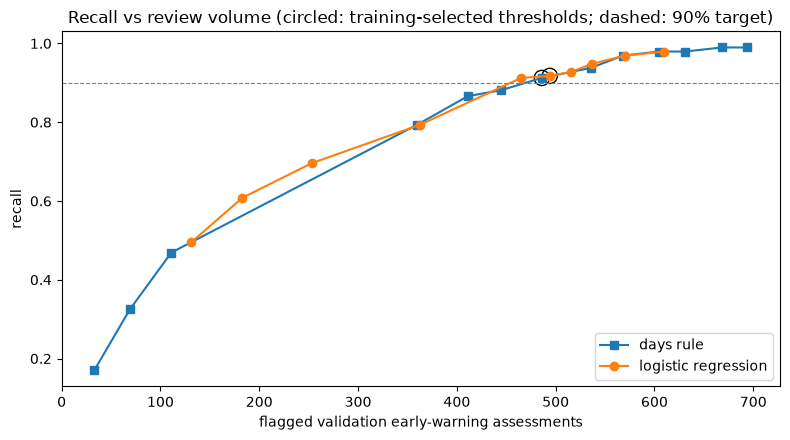

,assessments at exactly 5 days
checkpoint,
checkpoint_2,194
checkpoint_1,55


,data_version,method,threshold_value,threshold,training_selected,flagged_assessments,flagged_%,recall,precision,unique_tasks_flagged,at_risk_tasks_never_flagged
0,2,days rule,2.000,<= 2 days,False,33,3.195,0.170,1.000,33,121
1,2,days rule,3.000,<= 3 days,False,69,6.680,0.325,0.913,69,91
2,2,days rule,4.000,<= 4 days,False,111,10.745,0.469,0.820,111,63
3,2,days rule,5.000,<= 5 days,False,360,34.850,0.794,0.428,360,0
4,2,days rule,6.000,<= 6 days,False,411,39.787,0.866,0.409,360,0
5,2,days rule,7.000,<= 7 days,False,445,43.078,0.881,0.384,360,0
6,2,days rule,8.000,<= 8 days,True,486,47.047,0.912,0.364,366,0
7,2,days rule,9.000,<= 9 days,False,536,51.888,0.938,0.340,385,0
8,2,days rule,10.000,<= 10 days,False,568,54.985,0.969,0.331,396,0
9,2,days rule,11.000,<= 11 days,False,605,58.567,0.979,0.314,426,0


In [3]:
def summarize(flag, rows=predictions):
    """Review volume and outcomes when the given assessments are flagged."""
    y = rows["y"] == 1
    positives = int(y.sum())
    tp, fp = int((flag & y).sum()), int((flag & ~y).sum())
    tasks = rows.assign(flag=flag).groupby("request_id").agg(at_risk=("y", "max"), flagged=("flag", "any"))
    return {"flagged_assessments": int(flag.sum()), "flagged_%": flag.mean() * 100,
            "recall": tp / positives if positives else np.nan, "precision": tp / (tp + fp) if tp + fp else np.nan,
            "unique_tasks_flagged": int(tasks["flagged"].sum()),
            "at_risk_tasks_never_flagged": int((tasks["at_risk"].astype(bool) & ~tasks["flagged"]).sum())}


days = predictions["business_days_until_start"]
risk = predictions["risk_probability"]
rule_grid = pd.DataFrame([{"method": "days rule", "threshold_value": k, "threshold": f"<= {k} days",
                           "training_selected": k == DAYS_THRESHOLD, **summarize(days <= k)} for k in range(2, 15)])
# The training-selected model threshold is used at full precision; only its label is rounded
MODEL_GRID = sorted({0.05, 0.08, 0.10, 0.12, 0.15, 0.20, 0.30, 0.40, 0.50, MODEL_THRESHOLD})
model_grid = pd.DataFrame([{"method": "logistic regression", "threshold_value": t, "threshold": f">= {t:.4g}",
                            "training_selected": t == MODEL_THRESHOLD, **summarize(risk >= t)} for t in MODEL_GRID])
threshold_tradeoff = pd.concat([rule_grid, model_grid], ignore_index=True)
assert threshold_tradeoff["training_selected"].sum() == 2, "Each training-selected threshold should appear once."
threshold_tradeoff.insert(0, "data_version", DATA_VERSION)
threshold_tradeoff.to_csv(OUTPUT_DIR / "threshold_tradeoff_validation.csv", index=False)   # full precision

# Who enters the rule at exactly five business days (checkpoint 2 is always at five days)
five_days = predictions.loc[days == 5, "checkpoint"].value_counts().rename("assessments at exactly 5 days")

fig, ax = plt.subplots(figsize=(8, 4.5))
for method, marker in [("days rule", "s"), ("logistic regression", "o")]:
    sub = threshold_tradeoff[threshold_tradeoff["method"] == method].sort_values("flagged_assessments")
    ax.plot(sub["flagged_assessments"], sub["recall"], marker=marker, label=method)
    chosen = sub[sub["training_selected"]]
    ax.scatter(chosen["flagged_assessments"], chosen["recall"], s=120, facecolors="none", edgecolors="black")
ax.axhline(0.90, color="grey", ls="--", lw=0.8)
ax.set_xlabel("flagged validation early-warning assessments")
ax.set_ylabel("recall")
ax.set_title("Recall vs review volume (circled: training-selected thresholds; dashed: 90% target)")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "threshold_tradeoff_validation.png", dpi=120)
plt.show()
display(five_days.to_frame())
threshold_tradeoff.round(3)

## C. Matched-volume comparison

A fair way to compare the two rankings is at the same review volume. For each rule threshold, the model selects the same number of assessments, choosing its highest-risk ones. This is a **capacity-based comparison**, not a deployable probability threshold: a probability threshold can select a different number of assessments, especially when scores tie. Ties in the model's scores are broken by assessment ID; the table reports the size of the group of scores equal to each cutoff score and whether the selection splits that group, which is when the tie-breaker decides who is included.

In [4]:
# Matched volume: at each rule threshold's review volume N, the model selects its N highest-risk assessments.
# This is a capacity-based comparison, not a deployable probability threshold.
by_model = predictions.sort_values(["risk_probability", "assessment_id"], ascending=[False, True])
matched_rows = []
for k in range(2, 15):
    rule_flag = days <= k
    n = int(rule_flag.sum())
    model_flag = predictions.index.isin(by_model.index[:n])
    boundary = by_model["risk_probability"].iloc[n - 1] if n else np.nan
    tied_group = int((risk == boundary).sum()) if n else 0                       # scores equal to the cutoff score
    tied_selected = int((by_model["risk_probability"].iloc[:n] == boundary).sum()) if n else 0
    rule_s, model_s = summarize(rule_flag), summarize(pd.Series(model_flag, index=predictions.index))
    matched_rows.append({"review_volume": n, "rule_threshold": f"<= {k} days",
                         "rule_recall": rule_s["recall"], "model_recall_same_volume": model_s["recall"],
                         "rule_at_risk_tasks_missed": rule_s["at_risk_tasks_never_flagged"],
                         "model_at_risk_tasks_missed": model_s["at_risk_tasks_never_flagged"],
                         "cutoff_tied_group_size": tied_group,
                         "selection_splits_tied_group": 0 < tied_selected < tied_group})
matched_volume = pd.DataFrame(matched_rows)
matched_volume.insert(0, "data_version", DATA_VERSION)
matched_volume.round(4).to_csv(OUTPUT_DIR / "matched_volume_validation.csv", index=False)
print(f"Model probabilities: {risk.nunique():,} distinct values among {len(predictions):,} assessments; "
      "ties at a cutoff are broken by assessment ID")
matched_volume.round(3)

Model probabilities: 1,025 distinct values among 1,033 assessments; ties at a cutoff are broken by assessment ID


,data_version,review_volume,rule_threshold,rule_recall,model_recall_same_volume,rule_at_risk_tasks_missed,model_at_risk_tasks_missed,cutoff_tied_group_size,selection_splits_tied_group
0,2,33,<= 2 days,0.170,0.170,121,121,1,False
1,2,69,<= 3 days,0.325,0.314,91,93,1,False
2,2,111,<= 4 days,0.469,0.448,63,67,1,False
3,2,360,<= 5 days,0.794,0.789,0,10,1,False
4,2,411,<= 6 days,0.866,0.851,0,4,1,False
5,2,445,<= 7 days,0.881,0.897,0,1,1,False
6,2,486,<= 8 days,0.912,0.918,0,0,3,True
7,2,536,<= 9 days,0.938,0.948,0,0,1,False
8,2,568,<= 10 days,0.969,0.969,0,0,1,False
9,2,605,<= 11 days,0.979,0.979,0,0,1,False


## D. Review order

**This is a retrospective ordering experiment using saved validation assessments, not a simulation of a live queue.** The list combines assessments made on different dates, including two checkpoints for some tasks, which would never all have been available at once. It therefore does not establish which cases staff could have reviewed first on any particular date; a live queue would need an as-of date and only the information available then.

The rule's flags form one fixed list, reviewed in two orders: by the model's estimated risk (highest first) or by fewest days until start. For the first 10%, 25%, 50%, 75%, and 100% of the list, the table reports assessments reviewed, at-risk assessments reached, unique tasks reached, and at-risk tasks reached. Because a task can have two assessments, unique tasks are reported alongside assessments. In a live queue, a later assessment of a task already in the queue would update its existing entry rather than create a second review.

Many assessments share the same day count, so "fewest days first" needs a documented tie-breaker: assessment ID. A second table repeats the assessment-level coverage while averaging over every possible order within tied day counts. Averaged results can be fractional, so they are shown only as percentages. This check covers at-risk assessment counts only; it does not validate the task-level results.

In [5]:
# One fixed review list: the rule's flags. Two review orders over the same list.
LIST = predictions[predictions["days_rule"]].copy()
ORDERS = {
    "model risk (highest first)": LIST.sort_values(["risk_probability", "assessment_id"], ascending=[False, True]),
    "fewest days first": LIST.sort_values(["business_days_until_start", "assessment_id"]),   # documented tie-breaker
}
FRACTIONS = [0.10, 0.25, 0.50, 0.75, 1.00]
list_at_risk = int(LIST["y"].sum())
list_at_risk_tasks = LIST.loc[LIST["y"] == 1, "request_id"].nunique()
order_rows = []
for name, ordered in ORDERS.items():
    for f in FRACTIONS:
        reviewed = ordered.head(int(round(f * len(ordered))))
        order_rows.append({"order": name, "share_of_list_reviewed": f"{f:.0%}", "assessments_reviewed": len(reviewed),
                           "at_risk_assessments_reached": int(reviewed["y"].sum()),
                           "unique_tasks_reached": reviewed["request_id"].nunique(),
                           "at_risk_tasks_reached": reviewed.loc[reviewed["y"] == 1, "request_id"].nunique()})
queue_order = pd.DataFrame(order_rows)


def expected_recall_fewest_days(fraction):
    """Share of the list's at-risk assessments reached, averaged over every order within tied day counts."""
    budget = round(fraction * len(LIST))
    reached, used = 0.0, 0
    for _, group in LIST.groupby("business_days_until_start"):
        take = min(len(group), budget - used)
        if take <= 0:
            break
        reached += group["y"].sum() * take / len(group)        # a tied group gets credit for its expected share
        used += take
    return reached / list_at_risk


robustness = pd.DataFrame({
    "share_of_list_reviewed": [f"{f:.0%}" for f in FRACTIONS],
    "fewest days first, tie-broken by ID (% of at-risk reached)":
        queue_order.loc[queue_order["order"] == "fewest days first", "at_risk_assessments_reached"].to_numpy() / list_at_risk * 100,
    "fewest days first, ties averaged (% of at-risk reached)": [expected_recall_fewest_days(f) * 100 for f in FRACTIONS],
    "model risk (% of at-risk reached)":
        queue_order.loc[queue_order["order"] == "model risk (highest first)", "at_risk_assessments_reached"].to_numpy() / list_at_risk * 100,
})
queue_order.insert(0, "data_version", DATA_VERSION)
queue_order.to_csv(OUTPUT_DIR / "queue_order_validation.csv", index=False)
robustness.round(1).to_csv(OUTPUT_DIR / "queue_order_tie_check_validation.csv", index=False)
print(f"Fixed review list (rule flags): {len(LIST)} assessments, {list_at_risk} at risk, "
      f"{LIST['request_id'].nunique()} unique tasks, {list_at_risk_tasks} at-risk tasks")
display(queue_order)
robustness.round(1)

Fixed review list (rule flags): 486 assessments, 177 at risk, 366 unique tasks, 154 at-risk tasks


,data_version,order,share_of_list_reviewed,assessments_reviewed,at_risk_assessments_reached,unique_tasks_reached,at_risk_tasks_reached
0,2,model risk (highest first),10%,49,45,49,45
1,2,model risk (highest first),25%,122,91,121,91
2,2,model risk (highest first),50%,243,132,230,130
3,2,model risk (highest first),75%,364,156,319,145
4,2,model risk (highest first),100%,486,177,366,154
5,2,fewest days first,10%,49,45,49,45
6,2,fewest days first,25%,122,95,122,95
7,2,fewest days first,50%,243,125,243,125
8,2,fewest days first,75%,364,155,360,154
9,2,fewest days first,100%,486,177,366,154


,share_of_list_reviewed,"fewest days first, tie-broken by ID (% of at-risk reached)","fewest days first, ties averaged (% of at-risk reached)",model risk (% of at-risk reached)
0,10%,25.4,26.2,25.4
1,25%,53.7,53.0,51.4
2,50%,70.6,70.3,74.6
3,75%,87.6,87.6,88.1
4,100%,100.0,100.0,100.0


## E. Candidate review policies

Three candidate policies are compared on validation:

- **(a) Days rule alone:** flag assessments with 8 or fewer days until start; review fewest days first.
- **(b) Model alone:** flag assessments with an estimated risk of about 0.134 or higher.
- **(c) Rule decides the list, model sets the order:** the same fixed list as (a), reviewed highest model risk first.

Policies (a) and (c) flag exactly the same assessments, so their recall, precision, and review volume are identical; only the review order differs. Differences early in the order are retrospective validation findings. They do not demonstrate time savings or better onboarding outcomes. The final policy is chosen after the error and bias review, and frozen before the single test evaluation.

In [6]:
policy_a = summarize(predictions["days_rule"])
policy_b = summarize(predictions["logistic_regression"])
first_quarter = queue_order[(queue_order["share_of_list_reviewed"] == "25%")].set_index("order")
first_half = queue_order[(queue_order["share_of_list_reviewed"] == "50%")].set_index("order")
policies = pd.DataFrame([
    {"policy": f"(a) Days rule alone (<= {DAYS_THRESHOLD} days), fewest days first", **policy_a,
     "at_risk_reached_in_first_25%": int(first_quarter.loc["fewest days first", "at_risk_assessments_reached"]),
     "at_risk_reached_in_first_50%": int(first_half.loc["fewest days first", "at_risk_assessments_reached"])},
    {"policy": f"(b) Model alone (>= {MODEL_THRESHOLD:.3f})", **policy_b,
     "at_risk_reached_in_first_25%": np.nan, "at_risk_reached_in_first_50%": np.nan},
    {"policy": "(c) Days rule decides the list; model risk sets the order", **policy_a,
     "at_risk_reached_in_first_25%": int(first_quarter.loc["model risk (highest first)", "at_risk_assessments_reached"]),
     "at_risk_reached_in_first_50%": int(first_half.loc["model risk (highest first)", "at_risk_assessments_reached"])},
]).set_index("policy")
policies["at_risk_reached_in_first_25%"] = policies["at_risk_reached_in_first_25%"].astype("Int64")
policies["at_risk_reached_in_first_50%"] = policies["at_risk_reached_in_first_50%"].astype("Int64")
policies.insert(0, "data_version", DATA_VERSION)
policies.to_csv(OUTPUT_DIR / "candidate_policies_validation.csv")
policies.round(3)

,data_version,flagged_assessments,flagged_%,recall,precision,unique_tasks_flagged,at_risk_tasks_never_flagged,at_risk_reached_in_first_25%,at_risk_reached_in_first_50%
policy,,,,,,,,,
"(a) Days rule alone (<= 8 days), fewest days first",2,486,47.047,0.912,0.364,366,0,95,125
(b) Model alone (>= 0.134),2,494,47.822,0.918,0.360,368,0,<NA>,<NA>
(c) Days rule decides the list; model risk sets the order,2,486,47.047,0.912,0.364,366,0,91,132


## F. Human-review rules

Whatever policy is chosen, a person confirms every follow-up. Some cases need extra attention:

- **Overdue:** already at or past the deadline. These go to a **separate urgent-review list** and are always reviewed by the coordinator.
- **High impact close to start:** payroll, system access, or workplace access tasks with 5 or fewer days until start, which affect whether a new employee can be paid or start work. This is an invented prioritization, not a statement that other tasks are unimportant.
- **Methods disagree:** the rule flags the assessment but the model does not, or the reverse.
- **Near threshold:** the model's estimated risk is at least half its threshold but below it. This band is exploratory, not a confidence measure.

For cases **already on the review list**, these conditions appear as labels on the entry to inform the coordinator's judgment. Cases **not on the list** (for example, those flagged only by the model, or near the threshold but not flagged by the rule) are **audit-only**: they are recorded for monitoring and evaluation, but nobody reviews them unless a policy explicitly adds that review and its volume. Labels never add flags or change the review list.

The table counts each condition, how many were at risk, and how many were on the review list or audit-only.

In [7]:
# Review labels: shown on entries already in the review list; off-list cases are audit-only (no review, no extra flags)
HIGH_IMPACT_TASKS = ["payroll_setup", "system_access", "workplace_access"]
labels = pd.DataFrame({
    "near_threshold_not_flagged_by_model": predictions["risk_probability"].between(MODEL_THRESHOLD / 2, MODEL_THRESHOLD,
                                                                                   inclusive="left"),
    "rule_flags_model_does_not": predictions["days_rule"] & ~predictions["logistic_regression"],
    "model_flags_rule_does_not": predictions["logistic_regression"] & ~predictions["days_rule"],
    "high_impact_close_to_start": predictions["task_type"].isin(HIGH_IMPACT_TASKS) & (days <= 5),
})
on_list = predictions["days_rule"]
label_counts = pd.DataFrame({
    "assessments": labels.sum(),
    "at_risk": labels.apply(lambda col: int(predictions.loc[col, "y"].sum())),
    "on_review_list": labels.apply(lambda col: int((col & on_list).sum())),
    "off_list_audit_only": labels.apply(lambda col: int((col & ~on_list).sum())),
}).astype(int)
# Overdue assessments go to a separate urgent-review list, so all of them are reviewed
label_counts.loc["overdue (separate urgent-review list)"] = [int(overdue_02["assessments"]), int(overdue_02["assessments"]),
                                                            int(overdue_02["assessments"]), 0]
label_counts.insert(0, "data_version", DATA_VERSION)
label_counts.to_csv(OUTPUT_DIR / "review_labels_validation.csv")
label_counts

,data_version,assessments,at_risk,on_review_list,off_list_audit_only
near_threshold_not_flagged_by_model,2,93,11,24,69
rule_flags_model_does_not,2,24,2,24,0
model_flags_rule_does_not,2,32,3,0,32
high_impact_close_to_start,2,229,103,229,0
overdue (separate urgent-review list),2,24,24,24,0


## G. What the results show

**Five-day jump.** The rule's review volume rises from 111 assessments at 4 days to 360 at 5 days. Of the 249 assessments at exactly 5 days, 194 are checkpoint-2 assessments, which always occur at five days, and 55 are checkpoint-1 assessments with that count.

**Matched volume.** At the same review volume, neither method consistently does better. At 360 reviews, the rule reached 79.4% recall and missed no at-risk task, while the model reached 78.9% and missed 10 at-risk tasks; at 445 reviews, the model reached 89.7% against the rule's 88.1% and missed 1 task. From 568 reviews upward, both reached the same recall. At 486 reviews, the model's cutoff fell within a group of 3 equal scores, so the assessment-ID tie-breaker decided which of them were included.

**Review order.** On the rule's fixed list of 486 assessments (177 at risk, 154 at-risk tasks), reviewing fewest days first reached 95 at-risk assessments in the first quarter of the list, compared with 91 when ordered by model risk. By halfway, the model's order had reached 132 against 125. By three quarters, fewest days first had reached all 154 at-risk tasks, compared with 145 for the model's order. Averaging within tied day counts produced similar assessment-level coverage at the reported fractions. Task-level coverage remains dependent on the displayed ordering.

**Candidate policies.** Policies (a) and (c) flag the same 486 assessments (91.2% recall, 36.4% precision, 366 tasks); policy (b) flags 494 (91.8% recall, 36.0% precision, 368 tasks). None left an at-risk task without a warning.

**Review conditions.** All 24 overdue assessments would go to the urgent-review list. The 229 high-impact assessments close to the start date (103 at risk) were all already on the rule's list. The methods disagreed on 56 assessments: 24 flagged only by the rule (2 at risk), which are on the list, and 32 flagged only by the model (3 at risk), which would be audit-only under the rule-based policies.

**Interpretation.** Across review volumes and review positions, neither method consistently dominates. The model does not consistently outperform the rule on validation, and its added complexity has no demonstrated operational benefit yet. That supports considering the simpler days rule. These are retrospective validation findings using training-selected thresholds; the final policy will be chosen after the error and bias review and frozen before the single test evaluation. Differences in review order describe ordering only, not time savings or onboarding outcomes.